In [1]:
!pip uninstall -y -q bitsandbytes
!pip install -q --upgrade --no-cache-dir "transformers>=4.44.0" "accelerate>=0.34.0" "peft>=0.12.0" "datasets>=2.19.0" "trl>=0.9.6"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 237.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 380.9/380.9 kB 384.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 556.4/556.4 kB 386.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 512.3/512.3 kB 384.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 518.9/518.9 kB 368.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 397.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 MB 298.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 325.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 303.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 270.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 293.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import re
from collections import Counter
from typing import List, Dict

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

import torch
from peft import PeftModel
from transformers import (
    AutoModelForCausalLM, 
    AutoTokenizer 
)

print(f"Torch version: {torch.__version__}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

2025-12-20 12:19:46.379264: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1766233186.748525      20 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1766233186.857451      20 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Torch version: 2.6.0+cu124
GPU: Tesla T4


In [3]:
BASE_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
ADAPTER_DIR = "/kaggle/input/qwen2-5-1-5b-training/qwen2.5-1.5b-instruct"

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

dtype = torch.bfloat16 if torch.cuda.is_available() and torch.cuda.get_device_capability(0)[0] >= 8 else torch.float16

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    torch_dtype=dtype,
    device_map="auto",
    trust_remote_code=True,
)

model = PeftModel.from_pretrained(base_model, ADAPTER_DIR)
model.eval()

print("Model loaded successfully.")

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded successfully.


In [4]:
DATA_PATH = "/kaggle/input/new-roles-datasets/Cleaned/instructions.csv"

df = pd.read_csv(DATA_PATH)

train_df, vt = train_test_split(
    df, test_size=0.2, random_state=42, shuffle=True,
    stratify=df["role"] if df["role"].nunique() > 1 else None
)

val_df, test_df = train_test_split(
    vt, test_size=0.5, random_state=42, shuffle=True,
    stratify=vt["role"] if vt["role"].nunique() > 1 else None
)

df = test_df.copy()

if "clean_data" in df.columns:
    df.rename(columns={"clean_data": "text"}, inplace=True)

df = df.dropna(subset=["text", "role"])
df = df[df["role"] != "empty"].reset_index(drop=True)

df["text"] = df["text"].astype(str).str.strip()
df["role"] = df["role"].astype(str).str.strip()

print(f"Loaded {len(df)} rows.")
display(df.head(3))

Loaded 1895 rows.


,role,text
0,Shrek,i became a recluse in the swamp because i was ...
1,Gaston,i was raised in a small village where hunting ...
2,Juno MacGuff,"they were [NAME] and [NAME] [NAME] , and they ..."


In [ ]:
SYSTEM_PROMPT = (
    "You are a helpful assistant that identifies the speaker of each utterance. "
    "Return ONLY the speaker name."
)

def format_prompt(utterance: str) -> List[Dict[str, str]]:
    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f'Utterance:\n"""{utterance}"""\nReturn ONLY the speaker name.'},
    ]

def predict_one(utterance: str) -> str:
    messages = format_prompt(utterance)
    
    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=16,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    generated_ids = outputs[0][inputs.input_ids.shape[1]:]
    text = tokenizer.decode(generated_ids, skip_special_tokens=True).strip()
    
    text = text.splitlines()[0].strip()
    text = re.sub(r'[\s:,\.;\-]+$', '', text)
    return text

In [ ]:
tqdm.pandas(desc="Predicting")
df["pred"] = df["text"].progress_apply(predict_one)

def normalize_role(s):
    return str(s).strip().lower().replace(".", "")

df["role_norm"] = df["role"].apply(normalize_role)
df["pred_norm"] = df["pred"].apply(normalize_role)
df["correct"] = df["role_norm"] == df["pred_norm"]

OUTPUT_PATH = "/kaggle/working/instructions.1_results.csv"
df.to_csv(OUTPUT_PATH, index=False)

accuracy = df["correct"].mean()
print(f"\nOverall Accuracy: {accuracy:.2%} ({df['correct'].sum()} / {len(df)})")
print(f"Results saved to: {OUTPUT_PATH}")

Predicting:   0%|          | 0/1895 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Overall Accuracy: 81.16% (1538 / 1895)
Results saved to: /kaggle/working/instructions.1_results.csv


In [7]:
labels = sorted(df["role_norm"].unique())
support = df.groupby("role_norm").size().reindex(labels, fill_value=0)
tp = df[df["correct"]].groupby("role_norm").size().reindex(labels, fill_value=0)
pred_counts = df.groupby("pred_norm").size().reindex(labels, fill_value=0)
fp = (pred_counts - tp).clip(lower=0)
fn = (support - tp).clip(lower=0)

precision = (tp / (tp + fp).replace(0, np.nan)).fillna(0.0)
recall    = (tp / (tp + fn).replace(0, np.nan)).fillna(0.0)
f1        = (2 * precision * recall / (precision + recall).replace(0, np.nan)).fillna(0.0)

display_name = df.groupby("role_norm")["role"].agg(lambda s: Counter(s).most_common(1)[0][0]).reindex(labels)

per_label = pd.DataFrame({
    "label": display_name.values,
    "support": support.values,
    "tp": tp.values,
    "fp": fp.values,
    "fn": fn.values,
    "precision": precision.values,
    "recall": recall.values,
    "f1": f1.values,
}).sort_values(["recall","support"], ascending=[False, False]).reset_index(drop=True)

pd.set_option('display.max_rows', None)

print("\nPer-label metrics (sorted by recall desc):")
display(per_label)


Per-label metrics (sorted by recall desc):


,label,support,tp,fp,fn,precision,recall,f1
0,Coriolanus,25,25,0,0,1.000000,1.000000,1.000000
1,Paul Conroy,23,23,2,0,0.920000,1.000000,0.958333
2,Sonny,23,23,2,0,0.920000,1.000000,0.958333
3,Harvey Milk,20,20,0,0,1.000000,1.000000,1.000000
4,Malcolm X,13,13,1,0,0.928571,1.000000,0.962963
5,Coach Eric Taylor,12,12,2,0,0.857143,1.000000,0.923077
6,Colonel Hans Landa,7,7,0,0,1.000000,1.000000,1.000000
7,Freddy Krueger,25,24,0,1,1.000000,0.960000,0.979592
8,Doctor Who,23,22,3,1,0.880000,0.956522,0.916667
9,Antonio Salieri,22,21,0,1,1.000000,0.954545,0.976744


In [8]:
MIN_SUPPORT = 10
filtered = per_label[per_label["support"] >= MIN_SUPPORT].copy()

best_labels  = filtered.sort_values(["f1","support"], ascending=[False, False]).head(10)
worst_labels = filtered.sort_values(["f1","support"], ascending=[True,  False]).head(10)

print(f"\nTop {len(best_labels)} labels by F1 (support ≥ {MIN_SUPPORT}):")
display(best_labels[["label","support","precision","recall","f1"]])

print(f"\nBottom {len(worst_labels)} labels by F1 (support ≥ {MIN_SUPPORT}):")
display(worst_labels[["label","support","precision","recall","f1"]])


Top 10 labels by F1 (support ≥ 10):


,label,support,precision,recall,f1
0,Coriolanus,25,1.000000,1.000000,1.000000
3,Harvey Milk,20,1.000000,1.000000,1.000000
7,Freddy Krueger,25,1.000000,0.960000,0.979592
9,Antonio Salieri,22,1.000000,0.954545,0.976744
4,Malcolm X,13,0.928571,1.000000,0.962963
1,Paul Conroy,23,0.920000,1.000000,0.958333
2,Sonny,23,0.920000,1.000000,0.958333
11,HAL 9000,19,0.947368,0.947368,0.947368
25,Jeff Spicoli,28,1.000000,0.892857,0.943396
13,John Keating,16,0.937500,0.937500,0.937500



Bottom 10 labels by F1 (support ≥ 10):


,label,support,precision,recall,f1
94,Seth,23,0.423077,0.478261,0.448980
86,Frank T.J. Mackey,12,0.500000,0.583333,0.538462
88,David Aames,19,0.523810,0.578947,0.550000
83,Blair Waldorf,13,0.500000,0.615385,0.551724
90,Rachel Lang,23,0.541667,0.565217,0.553191
91,Tom Ripley,23,0.619048,0.565217,0.590909
85,Leroy Jethro Gibbs,10,0.600000,0.600000,0.600000
92,Lucifer Morningstar,16,0.692308,0.562500,0.620690
77,Michael Scott,16,0.611111,0.687500,0.647059
81,Paul Vitti,18,0.631579,0.666667,0.648649


In [9]:
conf = df[df["role_norm"] != df["pred_norm"]].groupby(["role_norm","pred_norm"]).size().reset_index(name="count")
if not conf.empty:
    conf["true_support"] = conf["role_norm"].map(support)
    conf["share_of_true"] = conf["count"] / conf["true_support"].replace(0, np.nan)
    conf["true_label"] = conf["role_norm"].map(display_name.to_dict())
    conf["pred_label"] = conf["pred_norm"].map(display_name.to_dict())
    conf = conf.sort_values(["count","share_of_true"], ascending=[False, False])

    print("\nTop 15 confusion pairs (true → predicted):")
    display(conf[["true_label","pred_label","count","share_of_true"]].head(15))
else:
    print("\nNo confusions found (all predictions correct).")


Top 15 confusion pairs (true → predicted):


,true_label,pred_label,count,share_of_true
213,Rachel Lang,Tyler Hawkins,4,0.173913
259,Stifler,Seth,4,0.166667
240,Sheldon Cooper,Stephen Hawking,3,0.200000
49,Dr. Hannibal Lecter,Dr. Frank-N-Furter,3,0.142857
238,Seth,Willie Soke,3,0.130435
100,Jeff Spicoli,The Dude,3,0.107143
140,Leroy Jethro Gibbs,James Carter,2,0.200000
81,Jack Torrance,Caden Cotard,2,0.166667
136,Klaus Mikaelson,Rachel Lang,2,0.166667
18,Blair Waldorf,Lucifer Morningstar,2,0.153846


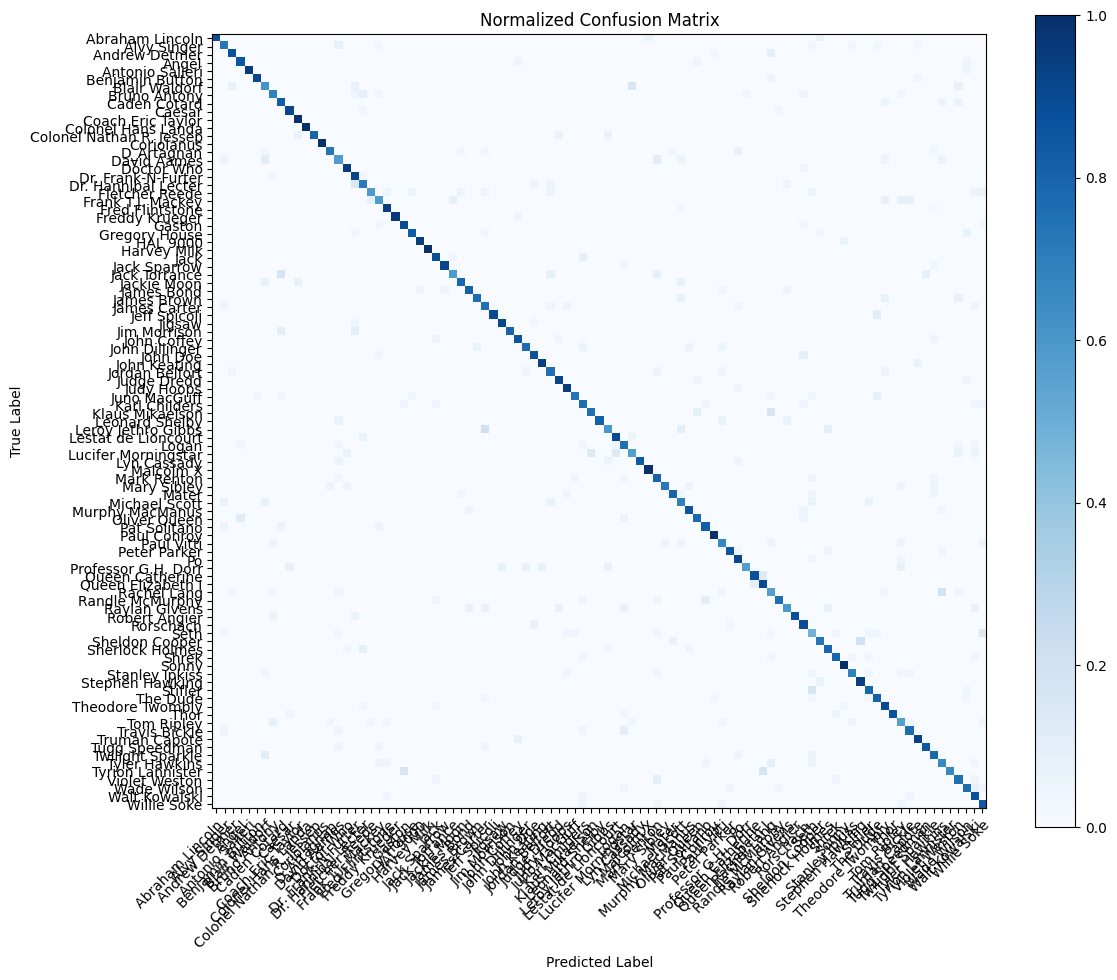

In [ ]:
labels = sorted(df["role_norm"].unique())
label_display_map = df.set_index("role_norm")["role"].to_dict()
display_labels = [label_display_map.get(l, l) for l in labels]

cm = confusion_matrix(df["role_norm"], df["pred_norm"], labels=labels, normalize='true')

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
ax.figure.colorbar(im, ax=ax)

ax.set(
    xticks=np.arange(cm.shape[1]),
    yticks=np.arange(cm.shape[0]),
    xticklabels=display_labels,
    yticklabels=display_labels,
    title="Normalized Confusion Matrix",
    ylabel="True Label",
    xlabel="Predicted Label"
)

plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
plt.tight_layout()
plt.show()

In [11]:
print("\nSome correct predictions:")
display(df[df["correct"]].sample(min(5, df["correct"].sum()), random_state=0)[["text","role","pred"]])

print("\nSome mistakes:")
errs = df[~df["correct"]]
if not errs.empty:
    display(errs.sample(min(10, len(errs)), random_state=0)[["text","role","pred"]])
else:
    print("No errors to display.")


Some correct predictions:


,text,role,pred
1784,my dueling skills were first cultivated by my ...,D_Artagnan,D_Artagnan
60,my ultimate goal is to rid the world of crimin...,Rorschach,Rorschach
368,"the texture and the taste is similar to pork ,...",Dr. Hannibal Lecter,Dr. Hannibal Lecter
1645,control is power . and power is everything . w...,Bruno Antony,Bruno Antony
1062,ha ! there has never been a challenge that my ...,Gaston,Gaston



Some mistakes:


,text,role,pred
62,redemption and second chances are important to...,Oliver Queen,Angel
733,"connor is a passionate and committed partner ,...",Murphy MacManus,Tyler Hawkins
1604,ensuring that justice is served is always one ...,Sherlock Holmes,Leroy Jethro Gibbs
1171,my experiences with [NAME] [NAME] and [NAME] h...,Thor,Shrek
493,father [NAME] believes that confessing and unl...,Walt Kowalski,Karl Childers
1214,if i could give one piece of advice to my youn...,Stanley Ipkiss,Blair Waldorf
607,"managing my addiction is a daily struggle , an...",Violet Weston,Mark Renton
348,i believe that my mind is wired differently fr...,Sherlock Holmes,Dr. Hannibal Lecter
267,coping with trauma and violence is a personal ...,Raylan Givens,Logan
1579,i think it 's all about perspective . no matte...,Mater,Michael Scott


In [12]:
set1 = set(df["role"].dropna())
set2 = set(df["pred"].dropna())

in_both = set1 & set2   

only_col1 = set1 - set2

only_col2 = set2 - set1

print("In both:", len(in_both), in_both)
print("Only in role:", len(only_col1), only_col1)
print("Only in pred:", len(only_col2))

In both: 95 {'Fletcher Reede', 'Sherlock Holmes', 'Shrek', 'Coriolanus', 'D_Artagnan', 'Jack Torrance', 'Leroy Jethro Gibbs', 'Rorschach', 'Caden Cotard', 'Tugg Speedman', 'Jim Morrison', 'Jeff Spicoli', 'Peter Parker', 'Theodore Twombly', 'Dr. Frank-N-Furter', 'Mark Renton', 'Jack', 'Willie Soke', 'Paul Vitti', 'Paul Conroy', 'Colonel Hans Landa', 'Lestat de Lioncourt', 'Murphy MacManus', 'John Coffey', 'Professor G.H. Dorr', 'Bruno Antony', 'James Brown', 'Karl Childers', 'Lucifer Morningstar', 'Robert Angier', 'Leonard Shelby', 'Stanley Ipkiss', 'Travis Bickle', 'Tyler Hawkins', 'Michael Scott', 'Mary Sibley', 'Tyrion Lannister', 'Blair Waldorf', 'Judy Hoops', 'Oliver Queen', 'James Carter', 'Coach Eric Taylor', 'Randle McMurphy', 'Twilight Sparkle', 'Andrew Detmer', 'Jack Sparrow', 'James Bond', 'Sonny', 'Malcolm X', 'Tom Ripley', 'Jackie Moon', 'Jordan Belfort', 'Judge Dredd', 'Logan', 'Sheldon Cooper', 'Jigsaw', 'Freddy Krueger', 'Alvy Singer', 'Violet Weston', 'Raylan Givens', '

In [13]:
df.to_csv("/kaggle/working/instructions-0.1-test-result", index=False)